# 4. Error, Order and Efficiency

The previous sections built methods of order 1, 2 and 4. This section makes the notion of order precise, shows how to measure it, compares methods by the work they need for a given accuracy, and explains how to **estimate the error of a computed solution when the exact solution is unknown**, which is always the case in practice. It ends with the error that no method can avoid: round-off.

Test problem: $y' = x + y$, $y(0) = 1$, exact solution $y = 2e^{x} - x - 1$. The Euler, Heun and RK4 functions are defined below exactly as in Sections 1–3.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

f = lambda x, y: x + y
exact = lambda x: 2 * np.exp(x) - x - 1

def euler(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        y[i + 1] = y[i] + h * f(x[i], y[i])
        x[i + 1] = x[i] + h
    return x, y

def heun(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h, y[i] + h * k1)
        y[i + 1] = y[i] + h / 2 * (k1 + k2)
        x[i + 1] = x[i] + h
    return x, y

def rk4(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h / 2, y[i] + h / 2 * k1)
        k3 = f(x[i] + h / 2, y[i] + h / 2 * k2)
        k4 = f(x[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        x[i + 1] = x[i] + h
    return x, y

## 4.1 Local truncation error, consistency and order

Every one-step method can be written as

$$y_{n+1} = y_n + h\,\Phi(x_n, y_n; h),$$

where $\Phi$ is the **increment function**: $\Phi = f(x_n, y_n)$ for Euler, $\Phi = \tfrac12(k_1 + k_2)$ for Heun, $\Phi = \tfrac16(k_1 + 2k_2 + 2k_3 + k_4)$ for RK4.

**Local truncation error.** Insert the exact solution into the method and see how far it fails to satisfy it:

$$\tau_{n+1} = y(x_{n+1}) - y(x_n) - h\,\Phi\big(x_n, y(x_n); h\big).$$

This is the error of a single step started from the exact value.

* The method is **consistent** if $\tau_{n+1}/h \to 0$ as $h \to 0$. Equivalently, $\Phi(x, y; 0) = f(x, y)$: for very small steps the method follows the true slope.
* The method has **order $p$** if $\tau_{n+1} = O(h^{p+1})$.

**Theorem (convergence of one-step methods).** If $\Phi$ satisfies a Lipschitz condition in $y$ with constant $L_\Phi$, and $|\tau_n| \le K h^{p+1}$ for all $n$, then

$$|y(x_n) - y_n| \le \frac{K h^{p}}{L_\Phi}\left(e^{L_\Phi(x_n - x_0)} - 1\right).$$

The proof is the same as the proof for Euler in [Section 1.5](01-eulers-method.ipynb): the error obeys $|e_{n+1}| \le (1 + hL_\Phi)|e_n| + Kh^{p+1}$. Two consequences:

* For one-step methods, **consistency alone guarantees convergence** (provided $f$ is Lipschitz, which makes $\Phi$ Lipschitz too).
* A local error of order $h^{p+1}$ gives a global error of order $h^p$: one power of $h$ is lost because about $1/h$ local errors accumulate.

## 4.2 Measuring the order

If the global error is $E(h) \approx Ch^{p}$, then

$$\frac{E(h)}{E(h/2)} \approx 2^{p}, \qquad \log E \approx \log C + p\log h.$$

So the order can be read off in two ways: from the **error ratio** when $h$ is halved, or from the **slope of a log–log plot** of error against $h$.

| Method | Order $p$ | Error ratio when $h$ is halved |
|---|---|---|
| Euler | 1 | ≈ 2 |
| Heun | 2 | ≈ 4 |
| RK4 | 4 | ≈ 16 |

We check this for the test problem by measuring the error at $x = 1$ (exact value $2e - 2 \approx 3.436564$).

In [2]:
hs = [0.2, 0.1, 0.05, 0.025, 0.0125]
methods = {"Euler": euler, "Heun": heun, "RK4": rk4}
cost_per_step = {"Euler": 1, "Heun": 2, "RK4": 4}
errors = {name: [] for name in methods}

for h in hs:
    n = round(1 / h)
    for name, method in methods.items():
        _, y = method(f, 0, 1, h, n)
        errors[name].append(abs(y[-1] - exact(1.0)))

print(f"{'h':>8}" + "".join(f"{m:>14}{'ratio':>8}" for m in methods))
for i, h in enumerate(hs):
    row = f"{h:8.4f}"
    for name in methods:
        e = errors[name]
        ratio = f"{e[i-1] / e[i]:8.2f}" if i else f"{'':>8}"
        row += f"{e[i]:14.3e}{ratio}"
    print(row)

for name, p in zip(methods, [1, 2, 4]):
    slope = np.polyfit(np.log(hs), np.log(errors[name]), 1)[0]
    print(f"{name:6s} observed order ≈ {slope:.2f}  (theory {p})")

       h         Euler   ratio          Heun   ratio           RK4   ratio
  0.2000     4.599e-01             3.115e-02             6.138e-05        
  0.1000     2.491e-01    1.85     8.402e-03    3.71     4.169e-06   14.73
  0.0500     1.300e-01    1.92     2.182e-03    3.85     2.716e-07   15.35
  0.0250     6.644e-02    1.96     5.558e-04    3.93     1.733e-08   15.67
  0.0125     3.359e-02    1.98     1.403e-04    3.96     1.095e-09   15.83
Euler  observed order ≈ 0.95  (theory 1)
Heun   observed order ≈ 1.95  (theory 2)
RK4    observed order ≈ 3.95  (theory 4)


## 4.3 Accuracy per unit of work

Smaller steps are not free. The real cost of a method is the number of times it evaluates $f$: $N$ for Euler, $2N$ for Heun and $4N$ for RK4. A fair comparison plots the error against that cost.

Euler  needs about    2,687,502 evaluations of f for error 1e-6
Heun   needs about        1,895 evaluations of f for error 1e-6
RK4    needs about           58 evaluations of f for error 1e-6


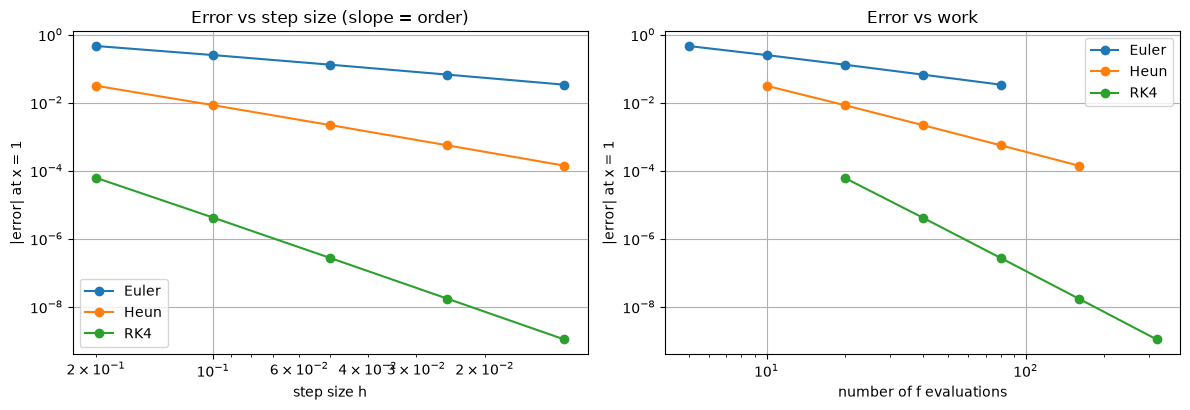

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name in methods:
    axes[0].loglog(hs, errors[name], "o-", label=name)
    evals = [cost_per_step[name] * round(1 / h) for h in hs]
    axes[1].loglog(evals, errors[name], "o-", label=name)
axes[0].invert_xaxis()
axes[0].set_xlabel("step size h"); axes[0].set_ylabel("|error| at x = 1")
axes[0].set_title("Error vs step size (slope = order)")
axes[1].set_xlabel("number of f evaluations"); axes[1].set_ylabel("|error| at x = 1")
axes[1].set_title("Error vs work")
for ax in axes:
    ax.legend()
plt.tight_layout()

# Work needed for an error of 1e-6, using E ≈ C h^p from the finest run
for name, p in zip(methods, [1, 2, 4]):
    evals = cost_per_step[name] * round(1 / hs[-1])
    need = evals * (errors[name][-1] / 1e-6) ** (1 / p)
    print(f"{name:6s} needs about {need:12,.0f} evaluations of f for error 1e-6")

**Takeaway.** In the right-hand plot, RK4's line lies far below the others: for any fixed amount of work it is far more accurate. To reach an error of $10^{-6}$, Euler needs about 2.7 million evaluations of $f$, Heun about 1,900 and RK4 about 60. Higher-order methods win whenever the solution is smooth.

## 4.4 Estimating the error when the exact solution is unknown

In real problems there is no exact solution to compare with. **Richardson's idea:** solve twice, with step sizes $h$ and $h/2$. Since $E(h) \approx Ch^p$,

$$y(b) - y_{h/2} \approx \frac{y_{h/2} - y_{h}}{2^{p} - 1}.$$

*Derivation.* Write $y(b) = y_h + Ch^p$ and $y(b) = y_{h/2} + C(h/2)^p$. Subtracting eliminates $y(b)$: $y_{h/2} - y_h = Ch^p(1 - 2^{-p})$, so $C(h/2)^p = (y_{h/2} - y_h)/(2^p - 1)$.

* The right-hand side is an **error estimate** for the finer solution, computed using only numerical results.
* Adding it to $y_{h/2}$ gives an **extrapolated** value that is more accurate than either run: one order higher.

Below we check the estimate against the true error for the test problem.

In [4]:
print(f"{'method':>6} {'y_h':>12} {'y_h/2':>12} {'estimated err':>14} {'true err':>12} {'extrapolated':>13} {'its err':>10}")
for name, p in [("Euler", 1), ("Heun", 2), ("RK4", 4)]:
    method = methods[name]
    _, y1 = method(f, 0, 1, 0.1, 10)
    _, y2 = method(f, 0, 1, 0.05, 20)
    est = (y2[-1] - y1[-1]) / (2**p - 1)
    true = exact(1.0) - y2[-1]
    extrap = y2[-1] + est
    print(f"{name:>6} {y1[-1]:12.8f} {y2[-1]:12.8f} {est:14.3e} {true:12.3e} "
          f"{extrap:13.8f} {abs(exact(1.0) - extrap):10.2e}")

method          y_h        y_h/2  estimated err     true err  extrapolated    its err
 Euler   3.18748492   3.30659541      1.191e-01    1.300e-01    3.42570590   1.09e-02
  Heun   3.42816169   3.43438211      2.073e-03    2.182e-03    3.43645558   1.08e-04
   RK4   3.43655949   3.43656339      2.598e-07    2.716e-07    3.43656365   1.18e-08


The estimated errors closely match the true errors, so the computed solutions **tell you how accurate they are**. Extrapolation also helps: the extrapolated Euler value is about 12 times more accurate than the finer Euler run, and the extrapolated RK4 value is accurate to about $10^{-8}$. This is the standard check in practice: **always re-run with half the step size and compare.**

## 4.5 Repeated extrapolation

For Euler's method the global error has a full expansion in powers of $h$:

$$y(b) = y_h + C_1 h + C_2 h^2 + C_3 h^3 + \cdots$$

One Richardson step removes the $h$ term. Applying it again to the extrapolated values removes the $h^2$ term, and so on. With step sizes $h, h/2, h/4, \dots$ this gives a triangular table

$$T_{i,0} = y_{h/2^i}, \qquad T_{i,k} = T_{i,k-1} + \frac{T_{i,k-1} - T_{i-1,k-1}}{2^k - 1},$$

in which column $k$ has order $k + 1$. (This is the same idea as Romberg integration.)

In [5]:
rows = 5
T = np.zeros((rows, rows))
for i in range(rows):
    h = 0.1 / 2**i
    T[i, 0] = euler(f, 0, 1, h, round(1 / h))[1][-1]
    for k in range(1, i + 1):
        T[i, k] = T[i, k - 1] + (T[i, k - 1] - T[i - 1, k - 1]) / (2**k - 1)

print("errors |y(1) − T[i, k]|   (rows: h = 0.1, 0.05, ...; columns: number of extrapolations)")
for i in range(rows):
    print(f"h = {0.1 / 2**i:<8.5f}" + "".join(f"{abs(exact(1) - T[i, k]):11.2e}" for k in range(i + 1)))
print(f"\nbest value {T[-1, -1]:.10f}, exact {exact(1):.10f}, using {sum(10 * 2**i for i in range(rows))} Euler steps in total")

errors |y(1) − T[i, k]|   (rows: h = 0.1, 0.05, ...; columns: number of extrapolations)
h = 0.10000    2.49e-01
h = 0.05000    1.30e-01   1.09e-02
h = 0.02500    6.64e-02   2.90e-03   2.52e-04
h = 0.01250    3.36e-02   7.52e-04   3.42e-05   3.02e-06
h = 0.00625    1.69e-02   1.91e-04   4.45e-06   2.06e-07   1.84e-08

best value 3.4365636385, exact 3.4365636569, using 310 Euler steps in total


Five cheap Euler runs combined by extrapolation give far more accuracy than any single Euler run in the table. The method relies on the error expansion being valid, so it needs a smooth solution and the same number of steps per unit length in every run.

## 4.6 Round-off error

The analysis so far assumes exact arithmetic. A computer stores numbers with a relative precision of about $\varepsilon$:

* single precision (`float32`): $\varepsilon \approx 6 \times 10^{-8}$
* double precision (`float64`, the NumPy default): $\varepsilon \approx 1.1 \times 10^{-16}$

Each step adds a rounding error of about $\varepsilon\,|y|$, and with $N = (b - x_0)/h$ steps these accumulate to about $N\varepsilon \propto \varepsilon/h$. The total error therefore behaves like

$$E(h) \approx C h^{p} + \frac{D\varepsilon}{h}.$$

The first term falls and the second rises as $h$ shrinks, so there is a **best step size**; making $h$ smaller than that makes the result *worse*. Setting $E'(h) = 0$ gives $h^{*} = \big(D\varepsilon / (pC)\big)^{1/(p+1)}$, which is larger for higher-order methods.

The effect is easy to see in single precision.

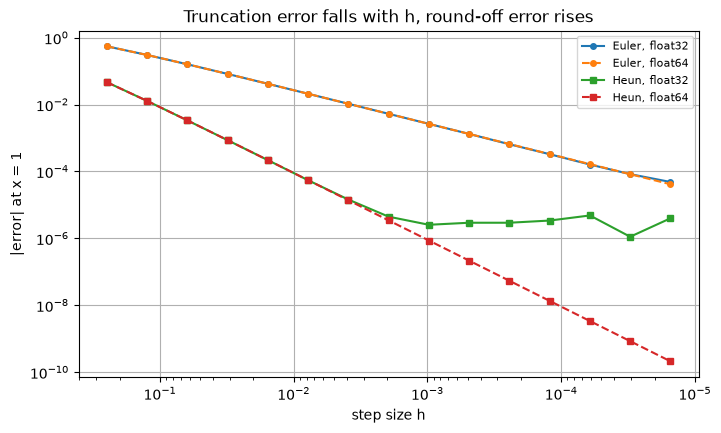

In [6]:
def euler_dtype(h, n, dtype):
    h, x, y = dtype(h), dtype(0), dtype(1)
    for _ in range(n):
        y = y + h * (x + y)
        x = x + h
    return y

def heun_dtype(h, n, dtype):
    h, x, y = dtype(h), dtype(0), dtype(1)
    half = dtype(0.5)
    for _ in range(n):
        k1 = x + y
        k2 = (x + h) + (y + h * k1)
        y = y + half * h * (k1 + k2)
        x = x + h
    return y

ks = range(2, 17)
hs_r = [2.0**-k for k in ks]
plt.figure(figsize=(8, 4.5))
for name, stepper, style in [("Euler", euler_dtype, "o"), ("Heun", heun_dtype, "s")]:
    for dtype, ls in [(np.float32, "-"), (np.float64, "--")]:
        errs = [abs(float(stepper(h, 2**k, dtype)) - exact(1.0)) for h, k in zip(hs_r, ks)]
        plt.loglog(hs_r, errs, marker=style, ls=ls, ms=4, label=f"{name}, {dtype.__name__}")
plt.gca().invert_xaxis()
plt.xlabel("step size h"); plt.ylabel("|error| at x = 1")
plt.title("Truncation error falls with h, round-off error rises")
plt.legend(fontsize=8);

In double precision (dashed) the error keeps falling over the whole range plotted. In single precision (solid) Heun's error follows the same line until $h \approx 2 \times 10^{-3}$ and then **stops improving**: at a few times $10^{-6}$, round-off dominates and smaller steps only add noise. Euler's truncation error is so much larger that, even with 65,000 steps, it is only just reaching that round-off level (the two Euler curves begin to separate at the smallest $h$). A higher-order method reaches the round-off floor with far fewer steps.

With `float64` the round-off floor is around $10^{-13}$ or below for these methods, which is why it rarely matters in practice, except for very long integrations or extremely small steps.

## 4.7 Summary

* Local truncation error $O(h^{p+1})$ $\Rightarrow$ global error $O(h^{p})$, for any consistent one-step method with Lipschitz $f$.
* Measure the order from error ratios ($\approx 2^p$) or the slope of a log–log plot.
* Compare methods by **error against number of $f$ evaluations**, not error against $h$.
* Richardson: two runs ($h$ and $h/2$) give an error estimate and a better, extrapolated value.
* Round-off sets a floor on the achievable accuracy; there is no point using steps far below the optimum.

## Exercises

1. An order 1 method has error $0.25$ with $h = 0.1$. Roughly what $h$ gives error $0.001$?
2. A method has error $3.2 \times 10^{-3}$ with step $h$ and $2.0 \times 10^{-4}$ with step $h/2$. What is its order?
3. Use Richardson extrapolation with Heun ($h = 0.2$ and $h = 0.1$) to estimate the error in $y(1)$ for the test problem. Compare with the true error.
4. Why is a plot of error against step size $h$ misleading when comparing Euler and RK4?

**Answers**

1. Error $\propto h$, so $h \approx 0.1 \times 0.001/0.25 = 0.0004$, which is 2,500 steps per unit of $x$.
2. Ratio $16 = 2^4$: order 4.
3. See the cell below.
4. One RK4 step costs four evaluations of $f$, one Euler step only one. Comparing at the same $h$ gives RK4 four times as much work. Plotting against $f$ evaluations compares equal effort.

In [7]:
_, ya = heun(f, 0, 1, 0.2, 5)
_, yb = heun(f, 0, 1, 0.1, 10)
est = (yb[-1] - ya[-1]) / (2**2 - 1)
print(f"3.  estimated error of the h = 0.1 run: {est:.3e},  true error: {exact(1) - yb[-1]:.3e}")
print(f"    extrapolated value {yb[-1] + est:.6f}, exact {exact(1):.6f}")

3.  estimated error of the h = 0.1 run: 7.582e-03,  true error: 8.402e-03
    extrapolated value 3.435743, exact 3.436564
